# Q3 Training Split Notebook 1

This notebook trains exactly two Q3 models:
- `EN-Softmax`
- `HI-NS`

Recommended workflow:
- Let one GPU session create and download `shared_english_corpus.csv` and `shared_hindi_corpus.csv` first.
- Upload those same two CSVs into the other GPU sessions before running their shared setup cell if you want guaranteed cache reuse.
- If you skip the upload step, this notebook still rebuilds the corpus deterministically from the same dataset and fixed seed.


## Initial Setup
Run the next cell once in a fresh Colab/GPU runtime before the Q3 code cells so the required packages are available.

In [2]:
import subprocess
import sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets", "indic-nlp-library"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "datasets"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '--upgrade', 'datasets'], returncode=0)

# **Question 3 : Word2vec [Total 1610 Marks]**

## **1. Introduction to Word2Vec**

## **Objective**
In this assignment, you will implement **Word2Vec (CBOW)** from scratch in PyTorch, using **three different strategies**:

1. **Full Softmax**
2. **Negative Sampling**
3. **Hierarchical Softmax** (Huffman-tree based)

You will train each variant on **two corpora**: **Hindi** and **English**

You are **not** allowed to use `gensim` or any pre-built Word2Vec implementation. You must write the CBOW model, the training loop, the Huffman tree, and the negative sampler yourself, in PyTorch/NumPy.

By the end of this part, you will:
*   Understand the concept of distributed word embeddings.
*   Learn about **CBOW** architectures.
*   Implement custom PyTorch `Dataset` classes for vectorized data loading.
*   Build a PyTorch `nn.Module` for Hierarchical Softmax, utilizing `torch.bmm` for batch matrix operations.
*   Train Word2Vec on a text corpus using the **Adam optimizer**.
*   Evaluate embeddings on an **analogy task** using a provided dataset.

---

### **What is Word2Vec?**
Word2Vec is a shallow neural network that learns **dense vector representations of words** such that semantically similar words lie close together in the embedding space.

The key idea: instead of representing words as one-hot vectors, we represent them as low-dimensional **embeddings** learned by predicting context words from a target word (or vice versa).

---
### CBOW Architecture

The **CBOW model** in Word2Vec learns word embeddings by predicting a center (target) word given its surrounding context words. It avoids one-hot vectors using index-based embedding lookup, making it both space- and time-efficient.

---

#### Visual Overview

**1. CBOW Model Structure**  
![CBOW Model Structure](https://miro.medium.com/v2/resize:fit:1100/format:webp/1*wrlax7j2AHUsFIgcpagLHg.png)




---

#### Intuition

Sentence:  
**"The cat sat on the mat"**, with **window size = 2**

If target word = `"cat"`, context = `["The", "sat"]`  
→ Training pairs:
- (`["The", "sat"]` → `cat`)

#### Architecture and Training Flow (with Index-based Input)

Let:  
- $ V $: size of the vocabulary  
- $ d $: embedding dimension  
-   C = $ c_1, c_2, \dots, c_m $ : list of context word indices  
-  $ t $: index of the target word  
-  $ E \in {R}^{V \times d} $ : input embedding matrix  
-  $ E' \in {R}^{V \times d} $ : output embedding matrix

Each context word $ c_i \in C $ is used to lookup a vector from $ E $, which are then averaged to form a single context embedding.

---

#### Step-by-Step Computation:

1. **Input**: Integer IDs of context words  C = $ {c_1, c_2, \dots, c_m} $

2. **Embedding Lookup**:

$$
h = \frac{1}{m} \sum_{i=1}^{m} E[c_i] \in \mathbb{R}^d
$$

3. **Score for Target Word $ t $**:

$$
\text{score}(t) = h^\top E'[t]
$$

4. **Softmax over Vocabulary**:

$$
P(w_t \mid \text{context}) = \frac{\exp(h^\top E'[t])}{\sum_{w=1}^{V} \exp(h^\top E'[w])}
$$

---

#### Objective Function

Given **context words** $ \{w_{t-k}, \dots, w_{t-1}, w_{t+1}, \dots, w_{t+k}\} $, the CBOW model aims to **predict the center word** \( w_t \).

$$
{L}_{\text{CBOW}} = \log P(w_t \mid w_{t-k}, \dots, w_{t-1}, w_{t+1}, \dots, w_{t+k})
$$

where


| Term &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;    | Description |
|---------|-------------|
| $ {L}_{\text{CBOW}} $ | The **log-likelihood** objective for predicting the center word $ w_t $ given its surrounding context words. |
| $ k $ | The **window size**, which defines how many words before and after the target word are used as context. |
| $ c_i $ | The **context word index** used for embedding lookup. |
| $ w_t $ | The **center word** (target word) to be predicted. |
| $ P(w_t \mid \text{context}) $ | The **conditional probability** of $ w_t $ being the correct word, given the context. |
| $ log P(w_t \mid \text{context}) $ | The **log-probability** of predicting $ w_t $ correctly given its context. |


---

#### Parameters Learned

- $ E \in {R}^{V \times d} $: Embedding matrix (input)
- $ E' \in {R}^{V \times d} $: Output matrix (used for prediction)

**Note**: Final embeddings are typically taken from matrix $ E $

---

### Summary

- **Input**: Integer indices of context words  
- **Output**: Predict index of target (center) word  
- **Lookup**: Embed each context word, then average  
- **Train**: With softmax or negative sampling  
- **Goal**: Words that appear in similar contexts should learn similar vector representations

---

### **Negative Sampling in Word2Vec**

---

#### Why Not Full Softmax?

In the original CBOW formulation, the softmax function is used to compute the probability of the target word given its context:

$$
P(w_t \mid \text{context}) = \frac{\exp(u_{w_t}^\top h)}{\sum_{w=1}^{V} \exp(u_w^\top h)}
$$

Where:
- $ h = \frac{1}{m}\sum_{i=1}^m E[c_i] $: averaged embedding of the context words
- $ u_{w_t} $: output embedding of the target word $ w_t $
- $ V $: vocabulary size

**Problem**:  
The denominator sums over **all words in the vocabulary** $ V $ — this is extremely slow for large corpora.

---

#### Solution: Negative Sampling

Instead of updating **all output weights**, **update only a small number of "negative samples"** along with the one positive pair.

---


#### Intuition

- For each training example (context $ C $, target $ w_t $):
  - Treat $ w_t $ as a **positive example**
  - Sample $ k $ random words $ \{w_1^{'}, w_2^{'}, ..., w_k^{'}\} $ from the vocabulary — these are **negative samples**
- The goal:
  - **Maximize** the probability of the real target word $ w_t $ given context $ h $
  - **Minimize** the probability of the negative samples $ w_i^{'} $ given the same context $ h $

---

#### Loss Function

For a context $C = \{c_1, \dots, c_m\}$ (averaged into $h$) and target word $w_t$, the **negative sampling loss** is:

$$
{L}_{\text{negative-sampling}} = -\log \sigma(u_{w_t}^\top h) - \sum_{i=1}^{k} \log \sigma(-u_{w_i^{'}}^\top h)
$$

Where:
- $ \sigma(x) = \frac{1}{1 + \exp(-x)} $  : sigmoid function
- $ h = \frac{1}{m}\sum_{i=1}^m E[c_i] $: averaged context embedding (from $E$)
- $ u_w $: output embedding of word $ w $ (from $E'$)
- $ w_t $: actual target/center word (positive sample)
- $ w_i^{'} $: i-th negative sample, sampled as a **fake target word**
- $ k $: number of negative samples

---

#### Training Workflow (Step-by-Step)

1. **Input**: context word indices $ C = \{c_1, \dots, c_m\} $, target word $ w_t $
2. **Get embeddings**:
   - $ h = \frac{1}{m}\sum_i E[c_i] \in {R}^d $ — averaged context vector from input matrix $ E $
   - $ u_{w_t} \in {R}^d $ from output matrix $ E'$
3. **Sample** $ k $ random words from vocabulary as negative (fake target) samples
4. **Compute loss** using the formula above
5. **Backpropagate** and update only:
   - $ E[c_i] $ for each $ c_i \in C $ (via $h$)
   - $ u_{w_t} $
   - $ u_{w_i^{'}} $ for all $ i \in [1, k] $
---




#### Why It Works

- Drastically reduces **computation time**.
- Still allows the model to learn **good semantic embeddings**.
- Scales to **billions of tokens** and **millions of words**.
- Enables **mini-batch training** with sparse updates.


---
### **Hierarchical Softmax in Word2Vec**

---

####  Why Another Alternative to Softmax?

Like Negative Sampling, **Hierarchical Softmax (HS)** addresses the computational inefficiency of the full softmax, especially for large vocabularies.

**Key Idea**:  
 Instead of scoring all words in the vocabulary, we build a **binary tree** and compute the probability of a word by traversing the path from the **root to that word's leaf**.

---

#### How Hierarchical Softmax Works

1. Build a **binary tree** where:
   - **Leaves** represent vocabulary words.
   - **Internal nodes** make **binary decisions**: left/right.

2. Each word is uniquely identified by a **path from the root to a leaf**.

3. The model:
   - Learns vector representations for each **internal node**.
   - Predicts the correct **binary decision** at each node in the path.

---

#### Example

Say the word **"sat"** is located along this binary path:
```
Root → Left → Right → Left → [sat]
```

We must predict:
- Step 1: Go **Left**
- Step 2: Go **Right**
- Step 3: Go **Left**

So the model predicts **a sequence of decisions** — **not** the word directly.

---

#### Mathematical Formulation

Let:
- $ w $ : target word to predict
- $ C = \{c_1, \dots, c_m\} $ : context word indices
- $ h = \frac{1}{m}\sum_{i=1}^m E[c_i] $ : averaged context embedding
- $ L(w) $ : length of the binary path to $ w $
- $ n_i $ : the $ i^{th} $ internal node along the path to $ w $
- $ s_i \in \{+1, -1\} $: direction at node $ n_i $ (+1 = left, -1 = right)
- $ v_{n_i} $ : vector associated with internal node $ n_i $
- $ \sigma(x) = \frac{1}{1 + \exp(-x)} $

Then:

$$
P(w \mid \text{context}) = \prod_{i=1}^{L(w)} \sigma\left( s_i \cdot v_{n_i}^\top h \right)
$$

---

#### Loss Function

For predicting target word $ w $ given context $ C $, the **loss is**:

$$
{L}_{\text{HS}} = - \sum_{i=1}^{L(w)} \log \sigma\left( s_i \cdot v_{n_i}^\top h \right)
$$

- Similar to Negative Sampling, the model uses **sigmoid** activations at each node, applied to the averaged context vector $h$ rather than a single word's embedding.
- Each decision is treated as a **binary classification task**.

---


#### Summary

- Hierarchical Softmax is a tree-based approximation to full softmax.
- Words are predicted by following binary paths.
- Each step in the path is trained via sigmoid + binary cross-entropy.
- Enables fast, full-vocab prediction with logarithmic complexity.

---



## **2. Task Explanation**

### **Goal**:

* Implement **Word2Vec (CBOW)** using **PyTorch**, train on each corpora separately (English and Hindi).
* Use the below code to download the dataset for training on each corpus.
  ```python

  from datasets import load_dataset

  train = load_dataset("Exploration-Lab/CS781", data_files={"train": "Assignment-1/train.parquet"}, split="train", token=token)

  test_en = load_dataset("Exploration-Lab/CS781", data_files={"en": "Assignment-1/analogy_test_en.parquet"}, split="en", token=token)
  test_hi = load_dataset("Exploration-Lab/CS781", data_files={"hi": "Assignment-1/analogy_test_hi.parquet"}, split="hi", token=token)
  ```


- After training your Word2Vec model, save the learned embeddings along with the vocabulary mappings using `pickle` (you must create total 6 embeddings i.e., for english and hindi using all three strategies):

  ```python
  import pickle

  with open("en_embeddings.pkl", "wb") as f:
      pickle.dump({
          "embeddings": embeddings,     # numpy  array of shape (vocab_size, embedding_dim)
          "vocab": vocab.itos,          # list: index → token
          "stoi": vocab.stoi            # dict: token → index
      }, f)

  with open("hi_embeddings.pkl", "wb") as f:
      pickle.dump({
          "embeddings": embeddings,     # numpy  array of shape (vocab_size, embedding_dim)
          "vocab": vocab.itos,          # list: index → token
          "stoi": vocab.stoi            # dict: token → index
      }, f)
  ```

- Evaluate the learned embeddings using a word analogy task and generate a result CSV file with predictions.


**Implementation Workflow Tips(not neccessary to follow these but suggested):**

- Test Small First: Always test your custom PyTorch Dataset, DataLoader, and model pipelines on a very small subset (e.g., a few hundred rows) to catch code and logic errors instantly.

- Scale Up to the Entire Corpus: Once your pipeline works flawlessly on the subset, run it on the entire corpus (not just 100,000 rows) to learn high-quality semantic representations.

- Run in Parallel: Training all 3 models on 2 languages sequentially will take time. Since the models are independent, we strongly suggest running multiple Jupyter notebooks or scripts in parallel for different variants/languages, and then merging your final code and results.

**Important**: While you are using PyTorch, you must manually construct the Huffman Tree logic, define the custom loss function using the hierarchical paths, and construct an optimized PyTorch `Dataset` that pre-computes context windows to prevent CPU bottlenecks. Do not use pre-built Word2Vec libraries like Gensim.






### Reproducibility & Hyperparameters
To ensure your results align with the expected standard solution, you must use the exact hyperparameters below for all training runs:
- Random Seed: 42 (Must fix torch, numpy, random)
- Epochs: 25
- Embedding Dimension ($d$): 100
- Window Size ($k$): 5
- Min Frequency Count: 2
- Optimizer: torch.optim.Adam
- Batch Size: 4096 (Note: If you experience OOM errors, you may drop the batch size )
- Context Pooling: The context embedding must be a strict linear average of the context vectors.




#### **1. Preprocessing [50 Marks]**
* Implement the incomplete data loading sections.
* Tokenize with `nltk.word_tokenize`.
* Lowercase all tokens.
* Apply minimum frequency pruning: `min_count = 2`.
* Construct vocabulary such that the most frequent word gets index `0`, next most frequent gets `1`, and so on.




In [3]:
# =========================================================================================
# SHARED SETUP for Q3 and Q4
# DO NOT MODIFY the random seeds, hyperparameters, or data loading functions.
# =========================================================================================

import hashlib
import os
import random
import time
import pickle
import heapq
from collections import Counter
from getpass import getpass

import nltk
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from datasets import load_dataset
from tqdm import tqdm

import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.manifold import TSNE

try:
    import umap.umap_ as umap
except ImportError:
    print("Please install umap-learn: pip install umap-learn")

nltk.download("punkt", quiet=True)
try:
    nltk.download("punkt_tab", quiet=True)
except Exception:
    pass

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# ---- Hyperparameters (DO NOT EDIT) ------------------------------------------------------
SHARED_SEED = 42
SHARED_N_PAIRS = None
MIN_TOKENS = 3
SHARED_MIN_COUNT = 2

# Separate caches for independently deduplicated corpora
EN_CACHE = "shared_english_corpus.csv"
HI_CACHE = "shared_hindi_corpus.csv"

EMBED_DIM = 100
WINDOW_SIZE = 5
EPOCHS = 25
BATCH_SIZE = 4096  # can be reduced
K_NEGATIVES = 5
LR_SOFTMAX = 0.01
LR_NS = 0.01
LR_HS = 0.01
hf_token = os.environ.get("HF_TOKEN", "").strip()

# =========================================================================================
# 1. DETERMINISTIC DATA LOADING
# =========================================================================================

def set_shared_seed(seed=SHARED_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    return seed


def shared_generator(seed=SHARED_SEED):  # use this in dataloader
    g = torch.Generator()
    g.manual_seed(seed)
    return g


def shared_tokenize(text):
    return nltk.word_tokenize(str(text).lower())


def get_hf_token():
    global hf_token
    if not hf_token:
        hf_token = getpass("Enter Hugging Face token: ").strip()
    if not hf_token:
        raise ValueError("A Hugging Face token is required to download the assignment dataset.")
    return hf_token


def load_shared_corpus(
    n_pairs=SHARED_N_PAIRS,
    seed=SHARED_SEED,
    en_cache=EN_CACHE,
    hi_cache=HI_CACHE
): 
    """
    Load the corpus.

    English and Hindi are treated as two independent corpora:
      - English duplicates are removed independently.
      - Hindi duplicates are removed independently.
      - Sentence length filtering is done independently.
      - English and Hindi are shuffled independently using the same seed.

    No English-Hindi pair alignment is maintained because the two languages
    are trained as separate models.
    """

    # -------------------------------------------------------------------------
    # Load original dataset
    # -------------------------------------------------------------------------
    if os.path.exists(en_cache) and os.path.exists(hi_cache):

        en_df = pd.read_csv(en_cache, keep_default_na=False)
        hi_df = pd.read_csv(hi_cache, keep_default_na=False)

        print(f"Loaded English corpus from {en_cache}")
        print(f"Loaded Hindi corpus from {hi_cache}")

    else:

        ds = load_dataset("Exploration-Lab/CS781", data_files={"train": "Assignment-1/train.parquet"}, split="train", token=get_hf_token())

        translations = ds["translation"]
        en_df = pd.DataFrame({"text": [x["en"] for x in translations]})
        hi_df = pd.DataFrame({"text": [x["hi"] for x in translations]})

        print(f"Original English sentences: {len(en_df):,}")
        print(f"Original Hindi sentences:   {len(hi_df):,}")

        # ---------------------------------------------------------------------
        # Remove NaN independently
        # ---------------------------------------------------------------------
        en_df = en_df.dropna(subset=['text'])
        hi_df = hi_df.dropna(subset=['text'])

        # ---------------------------------------------------------------------
        # Remove duplicates independently
        # ---------------------------------------------------------------------
        en_df = en_df.drop_duplicates(subset=['text'])
        hi_df = hi_df.drop_duplicates(subset=['text'])

        # ---------------------------------------------------------------------
        # Minimum sentence length independently
        # ---------------------------------------------------------------------
        en_df = en_df[en_df['text'].apply(lambda x: len(shared_tokenize(x)) >= MIN_TOKENS)]
        hi_df = hi_df[hi_df['text'].apply(lambda x: len(shared_tokenize(x)) >= MIN_TOKENS)]

        # ---------------------------------------------------------------------
        # Deterministic independent shuffling
        # ---------------------------------------------------------------------
        en_order = np.random.RandomState(seed).permutation(len(en_df))
        hi_order = np.random.RandomState(seed).permutation(len(hi_df))

        en_df = en_df.iloc[en_order].reset_index(drop=True)
        hi_df = hi_df.iloc[hi_order].reset_index(drop=True)

        # ---------------------------------------------------------------------
        # If n_pairs is specified, take that many from EACH language
        # ---------------------------------------------------------------------
        if n_pairs is not None:
            en_df = en_df.iloc[:n_pairs].reset_index(drop=True)
            hi_df = hi_df.iloc[:n_pairs].reset_index(drop=True)

        # ---------------------------------------------------------------------
        # Save separate caches
        # ---------------------------------------------------------------------
        en_df.to_csv(en_cache, index=False)
        hi_df.to_csv(hi_cache, index=False)

        print(f"Wrote {len(en_df):,} English sentences to {en_cache}")
        print(f"Wrote {len(hi_df):,} Hindi sentences to {hi_cache}")

    return en_df, hi_df
# =========================================================================================
# INITIALIZE
# =========================================================================================

set_shared_seed()

en_df, hi_df = load_shared_corpus()

# Separate corpora for separate language models
en_train_texts = en_df["text"].tolist()
hi_train_texts = hi_df["text"].tolist()

print("\nFinal training data:")
print(f"English: {len(en_train_texts):,} sentences")
print(f"Hindi:   {len(hi_train_texts):,} sentences")


Using device: cuda


Enter Hugging Face token:  ········


README.md: 0.00B [00:00, ?B/s]

Assignment-1/train.parquet:   0%|          | 0.00/190M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Original English sentences: 1,659,083
Original Hindi sentences:   1,659,083
Wrote 961,402 English sentences to shared_english_corpus.csv
Wrote 898,747 Hindi sentences to shared_hindi_corpus.csv

Final training data:
English: 961,402 sentences
Hindi:   898,747 sentences


In [4]:
# =========================================================================================
# 2. PREPROCESSING & VOCABULARY
# =========================================================================================

def preprocess_and_build_vocab(corpus_texts, min_count=SHARED_MIN_COUNT):
    """
    Tokenizes, lowercases, prunes by min_count, and assigns indices sorted by frequency.
    """
    print("Tokenizing corpus...")
    if isinstance(corpus_texts, list):
        tokens = [tok for s in corpus_texts if s for tok in shared_tokenize(s)]
    else:
        tokens = shared_tokenize(corpus_texts)

    freq_dict = Counter(tokens)
    filtered_tokens = [w for w, c in freq_dict.items() if c >= min_count]
    filtered_tokens.sort(key=lambda w: freq_dict[w], reverse=True)

    stoi = {w: i for i, w in enumerate(filtered_tokens)}
    
    # CHANGED: itos must be a list as per the assignment's pickle save format
    itos = filtered_tokens 
    
    frequencies = {stoi[w]: freq_dict[w] for w in filtered_tokens}

    print("Encoding corpus...")
    encoded_corpus = [stoi[w] for w in tokens if w in stoi]
    print(f" -> Vocab size: {len(stoi):,} | Corpus tokens (post-prune): {len(encoded_corpus):,}")
    
    return encoded_corpus, stoi, itos, frequencies

In [5]:
import numpy as np

def build_context_matrix(encoded_corpus, window_size, pad_id):
    """
    Constructs a vectorized context matrix using a sliding window.
    
    Returns:
        contexts: A (N, 2*window_size) NumPy array of context word IDs.
    """
    # 1. Convert to numpy array and pad with pad_id on both ends 
    # so the very first and last words can be used as target words
    corpus_arr = np.array(encoded_corpus, dtype=np.int32)
    padded_corpus = np.pad(corpus_arr, (window_size, window_size), constant_values=pad_id)
    
    # 2. Create sliding windows of size (2 * window_size + 1)
    # This generates an (N, 2w+1) matrix where the center column is the target word
    window_len = 2 * window_size + 1
    windows = np.lib.stride_tricks.sliding_window_view(padded_corpus, window_len)
    
    # 3. Delete the center column (the target word) to leave only the context words
    contexts = np.delete(windows, window_size, axis=1)
    
    return contexts

In [6]:
class CBOWDataset(Dataset):
    def __init__(self, encoded_corpus, window_size, vocab_size):
        self.vocab_size = vocab_size
        
        # We use vocab_size as the pad_id because word indices range from 0 to vocab_size - 1. 
        # This prevents padding from being confused with actual vocabulary words.
        pad_id = vocab_size 
        
        # Pre-compute contexts using your vectorized build_context_matrix function
        contexts = build_context_matrix(encoded_corpus, window_size, pad_id)
        
        # CHANGED: Use torch.from_numpy instead of torch.tensor to save ~1.4GB of RAM 
        # by sharing memory rather than duplicating the array.
        self.context_tensor = torch.from_numpy(contexts).long()
        self.target_tensor = torch.tensor(encoded_corpus, dtype=torch.long)

    def __len__(self):
        # The number of samples is exactly the number of target words
        return len(self.target_tensor)

    def __getitem__(self, i):
        # Returns (context_tensor, target_tensor) in O(1) time
        return self.context_tensor[i], self.target_tensor[i]

In [7]:
class CBOWBase(nn.Module):
    """Shared context-pooling logic for all CBOW variants."""
    def __init__(self, vocab_size, embed_dim):
        super().__init__()
        self.vocab_size = vocab_size

        # Initialize self.in_embeddings using nn.Embedding.
        # - The embedding dictionary size is (vocab_size + 1) to account for the padding token.
        # - padding_idx is set to vocab_size.
        self.in_embeddings = nn.Embedding(vocab_size + 1, embed_dim, padding_idx=vocab_size)
        
        # - Initialize the weights with a uniform distribution between (-0.5 / embed_dim) and (0.5 / embed_dim).
        bound = 0.5 / embed_dim
        nn.init.uniform_(self.in_embeddings.weight, -bound, bound)
        
        # - Use torch.no_grad() to explicitly set the weight of the padding index to all zeros.
        with torch.no_grad():
            self.in_embeddings.weight[vocab_size].fill_(0.0)

    def pool_context(self, contexts):
        """
        Calculates the average context embedding for a batch of context windows.

        Args:
            contexts: Tensor of shape (B, 2*window_size) containing context word IDs.

        Returns:
            h: Tensor of shape (B, embed_dim) representing the averaged context vectors.
        """
        # 1. Lookup the embeddings for the `contexts` tensor.
        # Shape: (B, 2*window_size, embed_dim)
        embeds = self.in_embeddings(contexts) 
        
        # 2. Identify which tokens are valid (i.e., not equal to self.vocab_size).
        # Shape: (B, 2*window_size)
        valid_mask = (contexts != self.vocab_size) 
        
        # 3. Count the valid tokens per row. (Hint: use .clamp(min=1) to prevent division by zero).
        # keepdim=True ensures the shape is (B, 1) so it broadcasts correctly when dividing.
        valid_counts = valid_mask.sum(dim=1, keepdim=True).clamp(min=1) 
        
        # 4. Sum the valid context embeddings and divide by the valid counts to compute the average.
        # Because we used padding_idx=self.vocab_size and set it to 0.0, the padding tokens 
        # add 0 to the sum and don't skew the results.
        sum_embeds = embeds.sum(dim=1)  # Shape: (B, embed_dim)
        h = sum_embeds / valid_counts   # Shape: (B, embed_dim)

        return h

    # CHANGED: Added a helper method to safely extract the NumPy array for your .pkl files!
    def get_embeddings(self):
        """
        Extracts the learned input embeddings to save as a deliverable.
        Returns a NumPy array of shape (vocab_size, embed_dim), excluding the padding token.
        """
        return self.in_embeddings.weight[:self.vocab_size].cpu().detach().numpy()

### **2. Part A — Full Softmax CBOW  [150 Marks]**

- Learning Rate: 0.01

- Epochs: 25

- Implement standard CBOW with full softmax over the vocabulary. Use an nn.Embedding for the input context and an nn.Linear(embed_dim, vocab_size, bias=False) for the output projection.


In [8]:
class CBOWFullSoftmax(CBOWBase):
    def __init__(self, vocab_size, embed_dim, tie_weights=False):
        super().__init__(vocab_size, embed_dim)
        self.tie_weights = tie_weights
        
        # Initialize output projection layer mapping from embed_dim to vocab_size without bias
        # Only initialize if we are NOT tying the weights
        if not self.tie_weights:
            self.out_projection = nn.Linear(embed_dim, vocab_size, bias=False)

    def forward(self, contexts, targets):
        # 1. Get the averaged context vector 'h' for the batch
        h = self.pool_context(contexts)
        
        # 2. Project 'h' to get logits for every word in the vocabulary
        if self.tie_weights:
            # EXPERIMENT DELIVERABLE: Use the input matrix as the output matrix
            # We slice [:self.vocab_size] to exclude the padding index vector!
            logits = F.linear(h, self.in_embeddings.weight[:self.vocab_size])
        else:
            # STANDARD DELIVERABLE: Use the separate output projection layer
            logits = self.out_projection(h)
        
        # 3. Calculate and return the standard Cross Entropy Loss
        loss = F.cross_entropy(logits, targets)
        
        return loss

In [9]:
def train_word2vec_softmax(encoded_corpus, stoi, epochs=EPOCHS, embed_dim=EMBED_DIM,
                            window=WINDOW_SIZE, batch_size=BATCH_SIZE, lr=LR_SOFTMAX, label=""):
    set_shared_seed()
    vocab_size = len(stoi)

    dataset = CBOWDataset(encoded_corpus, window, vocab_size)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, generator=shared_generator())

    model = CBOWFullSoftmax(vocab_size, embed_dim).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler(device=DEVICE.type)

    start_epoch, epoch_losses, prior_elapsed = load_checkpoint_if_present(
        label, model, optimizer, scaler, vocab_size, embed_dim
    )

    session_start = time.time()
    if start_epoch < epochs:
        model.train()
        print(f"--- Training {label} from epoch {start_epoch + 1} to {epochs} ---")
        for epoch in range(start_epoch, epochs):
            total_loss = 0.0
            for contexts, targets in tqdm(loader, desc=f"Epoch {epoch+1}/{epochs} [{label}]"):
                contexts, targets = contexts.to(DEVICE), targets.to(DEVICE)
                optimizer.zero_grad()
                with torch.autocast(device_type=DEVICE.type):
                    loss = model(contexts, targets)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                total_loss += loss.item()

            avg_loss = total_loss / len(loader)
            epoch_losses.append(avg_loss)
            print(f"Epoch {epoch+1}/{epochs} - Avg Loss: {avg_loss:.4f}")

            current_ep = epoch + 1
            if current_ep % CHECKPOINT_EVERY == 0 or current_ep == epochs:
                elapsed_time = prior_elapsed + (time.time() - session_start)
                save_checkpoint(label, current_ep, model, optimizer, scaler,
                                 epoch_losses, elapsed_time, vocab_size, embed_dim,
                                 auto_download=(current_ep == epochs))
        prior_elapsed += (time.time() - session_start)
    else:
        print(f"[{label}] checkpoint already covers all {epochs} epochs, skipping training.")

    total_time = prior_elapsed
    print(f"Training for {label} complete. Total logged time: {total_time:.2f}s ({total_time/60:.2f} min).")

    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker='o', linestyle='-', color='b')
    plt.title(f"Full Softmax CBOW Training Loss ({label})")
    plt.xlabel("Epoch"); plt.ylabel("Cross Entropy Loss")
    plt.grid(True, linestyle="--", alpha=0.7); plt.tight_layout()
    plt.savefig(f"loss_curve_{label}.png")
    plt.show()

    embeddings = model.get_embeddings()
    return embeddings, total_time, epoch_losses

### **3. Part B — Negative Sampling CBOW [200 Marks]**


- Learning Rate: 0.01
- Negative Samples ($k$): 5
- Epochs: 25
- Noise distribution: implement the standard unigram distribution raised to the 3/4 power, $P_n(w) \propto \text{count}(w)^{0.75}$, precomputed once as a sampling table.
- Vectorized negative sampling: sample a (batch_size, k) tensor of negative indices per batch using torch.randint on your precomputed table — no Python-level per-example loops.
- Vectorized loss: compute positive/negative logits with batched matrix ops (torch.bmm / einsum).
- Collision handling: document (in a code comment) what you do if a sampled negative accidentally equals the true positive w_o. You don't need to prevent it, just note the effect.

In [10]:
import numpy as np

def build_negative_sampling_table(frequencies, vocab_size, table_size=int(1e7)):
    """
    Builds the unigram^0.75 distribution table for negative sampling.
    
    Returns:
        table: An int64 NumPy array of size `table_size` containing word IDs sampled
               proportional to (count^0.75).
    """
    # 1. Extract counts in the exact order of vocabulary indices (0 to vocab_size - 1)
    counts = np.array([frequencies.get(i, 0) for i in range(vocab_size)])
    
    # 2. Apply the 3/4 power scaling as defined by the Word2Vec paper
    weights = counts ** 0.75
    
    # 3. Normalize to convert weights into probabilities
    probs = weights / np.sum(weights)
    
    # 4. Multiply probabilities by table_size to get the exact frequency in the table
    table_counts = np.round(probs * table_size).astype(int)
    
    # 5. Populate the table efficiently without loops
    table = np.repeat(np.arange(vocab_size), table_counts)
    
    # 6. Adjust exact array size (rounding can cause slight mismatch with exact table_size)
    if len(table) > table_size:
        table = table[:table_size]
    elif len(table) < table_size:
        # Pad with 0 (which is always a safe vocabulary index)
        table = np.pad(table, (0, table_size - len(table)), mode='constant', constant_values=0)
        
    return table.astype(np.int64)

In [11]:
class CBOWNegativeSampling(CBOWBase):
    # CHANGED: Added tie_weights parameter for the experiment deliverables
    def __init__(self, vocab_size, embed_dim, tie_weights=False):
        super().__init__(vocab_size, embed_dim)
        self.tie_weights = tie_weights
        
        # Initialize output embeddings (matrix E' in the theory).
        # Only initialize if we are NOT tying the weights
        if not self.tie_weights:
            self.out_embeddings = nn.Embedding(vocab_size, embed_dim)
            # Standard Word2Vec practice initializes the output weights to zeros.
            nn.init.zeros_(self.out_embeddings.weight)

    def forward(self, contexts, targets, negatives):
        """
        Args:
            contexts: (B, 2*window_size)
            targets: (B,)
            negatives: (B, k)
        """
        # 1. Get average context vector 'h'
        # Shape: (B, embed_dim)
        h = self.pool_context(contexts)
        
        # Reshape 'h' into a column vector for batched matrix multiplication
        # Shape: (B, embed_dim, 1)
        h_col = h.unsqueeze(2)

        # 2 & 3. Get embeddings based on the tie_weights experiment flag
        if self.tie_weights:
            # EXPERIMENT DELIVERABLE: Use the input matrix as the output matrix
            # Since targets and negatives only contain valid vocab indices, we can safely
            # pass them through the inherited in_embeddings layer.
            u_pos = self.in_embeddings(targets).unsqueeze(1)
            u_neg = self.in_embeddings(negatives)
        else:
            # STANDARD DELIVERABLE: Use separate output embeddings
            u_pos = self.out_embeddings(targets).unsqueeze(1)
            u_neg = self.out_embeddings(negatives)

        # 4. Compute batched dot products (scores)
        # Positive scores: (B, 1, embed_dim) bmm (B, embed_dim, 1) -> (B, 1, 1) -> reshape to (B,)
        # (CHANGED: Using .view(-1) is safer than .squeeze() in case batch_size happens to be 1)
        pos_scores = torch.bmm(u_pos, h_col).view(-1)
        
        # Negative scores: (B, k, embed_dim) bmm (B, embed_dim, 1) -> (B, k, 1) -> squeeze to (B, k)
        neg_scores = torch.bmm(u_neg, h_col).squeeze(2)

        # 5. Compute Vectorized Loss using Numerically Stable Log-Sigmoid
        # L = -log(sigmoid(pos_scores)) - sum[ log(sigmoid(-neg_scores)) ]
        pos_loss = -F.logsigmoid(pos_scores)
        neg_loss = -F.logsigmoid(-neg_scores).sum(dim=1)

        # 6. Collision Handling (Documentation as requested)
        # What happens if a negative sample accidentally equals the true positive w_o?
        # -> We do not explicitly prevent it. If a collision occurs, the model computes conflicting
        #    gradients for that specific word (pushing the dot product up via pos_loss, and pulling it 
        #    down via neg_loss). Because k is small relative to a massive vocabulary, these collisions 
        #    are statistically rare and act as acceptable stochastic noise during training.

        # Return the mean loss for the batch
        return (pos_loss + neg_loss).mean()

In [12]:
def train_word2vec_ns(encoded_corpus, stoi, freq, epochs=EPOCHS, embed_dim=EMBED_DIM,
                       window=WINDOW_SIZE, k_negatives=K_NEGATIVES, batch_size=BATCH_SIZE,
                       lr=LR_NS, tie_weights=False, label=""):
    set_shared_seed()
    vocab_size = len(stoi)

    table = build_negative_sampling_table(freq, vocab_size)
    table_tensor = torch.tensor(table, dtype=torch.long, device=DEVICE)
    table_size = len(table_tensor)

    dataset = CBOWDataset(encoded_corpus, window, vocab_size)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, generator=shared_generator())

    model = CBOWNegativeSampling(vocab_size, embed_dim, tie_weights=tie_weights).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler(device=DEVICE.type)

    start_epoch, epoch_losses, prior_elapsed = load_checkpoint_if_present(
        label, model, optimizer, scaler, vocab_size, embed_dim
    )

    session_start = time.time()
    if start_epoch < epochs:
        model.train()
        print(f"--- Training {label} from epoch {start_epoch + 1} to {epochs} ---")
        for epoch in range(start_epoch, epochs):
            total_loss = 0.0
            for contexts, targets in tqdm(loader, desc=f"Epoch {epoch+1}/{epochs} [{label}]"):
                contexts, targets = contexts.to(DEVICE), targets.to(DEVICE)
                current_batch_size = contexts.size(0)
                rand_indices = torch.randint(0, table_size, (current_batch_size, k_negatives), device=DEVICE)
                negatives = table_tensor[rand_indices]

                optimizer.zero_grad()
                with torch.autocast(device_type=DEVICE.type):
                    loss = model(contexts, targets, negatives)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                total_loss += loss.item()

            avg_loss = total_loss / len(loader)
            epoch_losses.append(avg_loss)
            print(f"Epoch {epoch+1}/{epochs} - Avg Loss: {avg_loss:.4f}")

            current_ep = epoch + 1
            if current_ep % CHECKPOINT_EVERY == 0 or current_ep == epochs:
                elapsed_time = prior_elapsed + (time.time() - session_start)
                save_checkpoint(label, current_ep, model, optimizer, scaler,
                                 epoch_losses, elapsed_time, vocab_size, embed_dim,
                                 auto_download=(current_ep == epochs))
        prior_elapsed += (time.time() - session_start)
    else:
        print(f"[{label}] checkpoint already covers all {epochs} epochs, skipping training.")

    total_time = prior_elapsed
    print(f"Training for {label} complete. Total logged time: {total_time:.2f}s ({total_time/60:.2f} min).")

    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker='o', linestyle='-', color='green')
    plt.title(f"Negative Sampling CBOW Training Loss ({label})")
    plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.grid(True, linestyle="--", alpha=0.7); plt.tight_layout()
    plt.savefig(f"loss_curve_ns_{label}.png")
    plt.show()

    embeddings = model.get_embeddings()
    return embeddings, total_time, epoch_losses


### **4. Part C — Hierarchical Softmax CBOW [200 Marks]**



- Learning Rate: 0.01

- Epochs: 25

- Huffman Tree: Build a Huffman tree from word frequencies using a min-heap (heapq).

    - Left child = code +1, right child = code -1.

    - Print the number of leaf nodes, internal nodes, and total nodes upon creation.

- Pad all tree paths and codes to the maximum path length so they can be grouped into PyTorch tensors. Create a binary mask array so padded indices don't contribute to the loss.

- Vectorized Forward Pass: Use nn.Embedding for internal tree nodes. Use torch.bmm to compute dot products between the context vector and every node along a word's path simultaneously.


In [13]:
import heapq
import numpy as np

class HuffmanNode:
    __slots__ = ("freq", "word_idx", "left", "right", "internal_idx")
    def __init__(self, freq, word_idx=None):
        self.freq = freq
        self.word_idx = word_idx
        self.left = None
        self.right = None
        self.internal_idx = None

    def __lt__(self, other):
        return self.freq < other.freq

def build_huffman_tree(frequencies):
    """
    Builds a Huffman tree from the given word frequencies.
    Prints the number of leaf nodes, internal nodes, and total nodes.
    
    Returns:
        paths: dict mapping word_idx -> list of internal node indices
        codes: dict mapping word_idx -> list of binary decisions (+1/-1)
        internal_idx: Total number of internal nodes created
    """
    # 1. Initialize Min-Heap with leaf nodes
    heap = []
    for word_idx, freq in frequencies.items():
        heapq.heappush(heap, HuffmanNode(freq, word_idx))
        
    leaf_nodes = len(frequencies)
    internal_nodes = 0
    
    # 2. Build the Tree
    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)
        
        parent = HuffmanNode(left.freq + right.freq)
        parent.left = left
        parent.right = right
        parent.internal_idx = internal_nodes
        internal_nodes += 1
        
        heapq.heappush(heap, parent)
        
    total_nodes = leaf_nodes + internal_nodes
    
    # Print counts as instructed
    print(f"Huffman Tree -> Leaf nodes: {leaf_nodes}, Internal nodes: {internal_nodes}, Total nodes: {total_nodes}")
    
    root = heap[0]
    paths = {}
    codes = {}
    
    # 3. Traverse the tree to extract paths and codes
    def traverse(node, current_path, current_code):
        if node is None:
            return
        
        # If it's a leaf node, save the path and code
        if node.word_idx is not None:
            paths[node.word_idx] = list(current_path)
            codes[node.word_idx] = list(current_code)
            return
        
        # Internal node traversal
        current_path.append(node.internal_idx)
        
        # Left child = +1
        current_code.append(1)
        traverse(node.left, current_path, current_code)
        current_code.pop()
        
        # Right child = -1
        current_code.append(-1)
        traverse(node.right, current_path, current_code)
        current_code.pop()
        
        current_path.pop()
        
    traverse(root, [], [])
    
    return paths, codes, internal_nodes

def pad_paths_codes(paths, codes, vocab_size, num_internal_nodes):
    """
    Pads the tree paths and codes to max_len to allow batched PyTorch operations.
    
    Returns:
        padded_paths: NumPy array (vocab_size, max_len) padded with `num_internal_nodes`
        padded_codes: NumPy array (vocab_size, max_len) padded with 0
        masks: NumPy array (vocab_size, max_len) where 1 = valid, 0 = padding
    """
    # Find the maximum path length in the tree
    max_len = max(len(p) for p in paths.values())
    
    # Initialize arrays with padding values
    # paths are padded with `num_internal_nodes` (this acts as the padding index for the embedding layer)
    padded_paths = np.full((vocab_size, max_len), num_internal_nodes, dtype=np.int64)
    # codes are padded with 0 (since valid are +1/-1)
    padded_codes = np.zeros((vocab_size, max_len), dtype=np.int64)
    # masks are 0 for padding
    masks = np.zeros((vocab_size, max_len), dtype=np.float32)
    
    for i in range(vocab_size):
        p = paths[i]
        c = codes[i]
        length = len(p)
        
        # Insert the valid sequences into the arrays
        padded_paths[i, :length] = p
        padded_codes[i, :length] = c
        masks[i, :length] = 1.0  # 1 indicates valid path
        
    return padded_paths, padded_codes, masks

In [14]:
class CBOWHierarchicalSoftmax(CBOWBase):
    def __init__(self, vocab_size, num_internal_nodes, embed_dim):
        super().__init__(vocab_size, embed_dim)
        
        # Initialize internal node embeddings. 
        # Size is (num_internal_nodes + 1) because pad_paths_codes padded the arrays 
        # with the value `num_internal_nodes`. We use this as our padding index.
        self.internal_embeddings = nn.Embedding(
            num_internal_nodes + 1, 
            embed_dim, 
            padding_idx=num_internal_nodes
        )
        
        # Initialize output representations (internal nodes) to zero, as is standard in Word2Vec.
        nn.init.zeros_(self.internal_embeddings.weight)

    def forward(self, contexts, paths, codes, masks):
        """
        Args:
            contexts: (B, 2*window_size)
            paths: (B, max_len) - indices of internal nodes
            codes: (B, max_len) - (+1 or -1) binary decisions
            masks: (B, max_len) - 1.0 for valid path steps, 0.0 for padding
        """
        # 1. Get average context vector 'h'
        # Shape: (B, embed_dim)
        h = self.pool_context(contexts)
        
        # Reshape 'h' into a column vector for batched matrix multiplication
        # Shape: (B, embed_dim, 1)
        h_col = h.unsqueeze(2)

        # 2. Get embeddings for the internal nodes along the path
        # Shape: (B, max_len, embed_dim)
        v_n = self.internal_embeddings(paths)

        # 3. Compute batched dot products (scores for each node in the path)
        # (B, max_len, embed_dim) bmm (B, embed_dim, 1) -> (B, max_len, 1) -> squeeze to (B, max_len)
        scores = torch.bmm(v_n, h_col).squeeze(2)

        # 4. Multiply scores by the true decisions (+1 for left, -1 for right)
        # We cast codes to float since they will be multiplied by float scores.
        codes = codes.float()
        
        # 5. Compute Vectorized Loss using Numerically Stable Log-Sigmoid
        # For Hierarchical Softmax, the objective is to maximize log(sigmoid(code * score)).
        # Loss = -sum(logsigmoid(code * score) * mask)
        log_probs = F.logsigmoid(codes * scores)
        
        # 6. Apply masks so padding tokens (0.0) don't contribute to the loss sum
        masked_log_probs = log_probs * masks
        
        # Sum the log probabilities along the length of the path (dim=1) and take the negative
        path_loss = -masked_log_probs.sum(dim=1)

        # Return the mean loss for the batch
        return path_loss.mean()

In [15]:
def train_word2vec_hs(encoded_corpus, stoi, freq, epochs=EPOCHS, embed_dim=EMBED_DIM,
                       window=WINDOW_SIZE, batch_size=BATCH_SIZE, lr=LR_HS, label=""):
    set_shared_seed()
    vocab_size = len(stoi)

    paths, codes, num_internal_nodes = build_huffman_tree(freq)
    padded_paths, padded_codes, masks = pad_paths_codes(paths, codes, vocab_size, num_internal_nodes)
    paths_tensor = torch.tensor(padded_paths, dtype=torch.long, device=DEVICE)
    codes_tensor = torch.tensor(padded_codes, dtype=torch.long, device=DEVICE)
    masks_tensor = torch.tensor(masks, dtype=torch.float32, device=DEVICE)

    dataset = CBOWDataset(encoded_corpus, window, vocab_size)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, generator=shared_generator())

    model = CBOWHierarchicalSoftmax(vocab_size, num_internal_nodes, embed_dim).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler(device=DEVICE.type)

    start_epoch, epoch_losses, prior_elapsed = load_checkpoint_if_present(
        label, model, optimizer, scaler, vocab_size, embed_dim
    )

    session_start = time.time()
    if start_epoch < epochs:
        model.train()
        print(f"--- Training {label} from epoch {start_epoch + 1} to {epochs} ---")
        for epoch in range(start_epoch, epochs):
            total_loss = 0.0
            for contexts, targets in tqdm(loader, desc=f"Epoch {epoch+1}/{epochs} [{label}]"):
                contexts, targets = contexts.to(DEVICE), targets.to(DEVICE)
                b_paths = paths_tensor[targets]
                b_codes = codes_tensor[targets]
                b_masks = masks_tensor[targets]

                optimizer.zero_grad()
                with torch.autocast(device_type=DEVICE.type):
                    loss = model(contexts, b_paths, b_codes, b_masks)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                total_loss += loss.item()

            avg_loss = total_loss / len(loader)
            epoch_losses.append(avg_loss)
            print(f"Epoch {epoch+1}/{epochs} - Avg Loss: {avg_loss:.4f}")

            current_ep = epoch + 1
            if current_ep % CHECKPOINT_EVERY == 0 or current_ep == epochs:
                elapsed_time = prior_elapsed + (time.time() - session_start)
                save_checkpoint(label, current_ep, model, optimizer, scaler,
                                 epoch_losses, elapsed_time, vocab_size, embed_dim,
                                 auto_download=(current_ep == epochs))
        prior_elapsed += (time.time() - session_start)
    else:
        print(f"[{label}] checkpoint already covers all {epochs} epochs, skipping training.")

    total_time = prior_elapsed
    print(f"Training for {label} complete. Total logged time: {total_time:.2f}s ({total_time/60:.2f} min).")

    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker='o', linestyle='-', color='purple')
    plt.title(f"Hierarchical Softmax CBOW Training Loss ({label})")
    plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.grid(True, linestyle="--", alpha=0.7); plt.tight_layout()
    plt.savefig(f"loss_curve_hs_{label}.png")
    plt.show()

    embeddings = model.get_embeddings()
    return embeddings, total_time, epoch_losses

In [16]:
import os
import pickle
import torch

CHECKPOINT_EVERY = 5  # epochs


def checkpoint_path(label):
    return f"checkpoint_{label}.pt"


def save_checkpoint(label, epoch, model, optimizer, scaler, epoch_losses,
                    elapsed_time, vocab_size, embed_dim, auto_download=False):
    path = checkpoint_path(label)
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "epoch_losses": epoch_losses,
        "elapsed_time": elapsed_time,
        "label": label,
        "vocab_size": vocab_size,
        "embed_dim": embed_dim,
    }, path)
    print(f"[checkpoint] saved -> {path} (epoch {epoch})")

    if auto_download:
        try:
            from google.colab import files
            files.download(path)
            print(f"[checkpoint] final checkpoint download triggered for {path}.")
        except ImportError:
            print(f"[checkpoint] not in Colab — final checkpoint is on local disk at {path}.")
        except Exception as e:
            print(f"[checkpoint] final checkpoint download failed ({e}); grab {path} manually.")


def load_checkpoint_if_present(label, model, optimizer, scaler, vocab_size, embed_dim):
    path = checkpoint_path(label)
    if not os.path.exists(path):
        print(f"[checkpoint] none found for {label}, starting from epoch 0.")
        return 0, [], 0.0

    ckpt = torch.load(path, map_location=DEVICE)

    if ckpt.get("vocab_size") != vocab_size or ckpt.get("embed_dim") != embed_dim:
        raise ValueError(
            f"[checkpoint] MISMATCH for {label}: checkpoint has "
            f"vocab_size={ckpt.get('vocab_size')}, embed_dim={ckpt.get('embed_dim')}, "
            f"but this run has vocab_size={vocab_size}, embed_dim={embed_dim}. "
            "This is the wrong checkpoint for this run — delete it, don't resume with it."
        )

    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    scaler.load_state_dict(ckpt["scaler_state_dict"])
    start_epoch = ckpt["epoch"]
    epoch_losses = ckpt["epoch_losses"]
    elapsed_time = ckpt.get("elapsed_time", 0.0)
    print(f"[checkpoint] resumed {label} from epoch {start_epoch} "
          f"({elapsed_time/60:.1f} min already logged).")
    return start_epoch, epoch_losses, elapsed_time


def upload_checkpoint(label):
    """Run this only when resuming after a crash/disconnect."""
    try:
        from google.colab import files
    except ImportError as exc:
        raise RuntimeError("Checkpoint upload helper is intended for Google Colab.") from exc

    uploaded = files.upload()
    expected = checkpoint_path(label)
    for fname in uploaded:
        if fname != expected:
            os.rename(fname, expected)
    print(f"[checkpoint] restored {expected} into the runtime.")


def save_pkl(filename, embeddings, vocab, stoi, epoch_losses=None, total_time=None,
             label=None, auto_download=True):
    payload = {
        "embeddings": embeddings,
        "vocab": vocab,
        "itos": vocab,
        "stoi": stoi,
        "epoch_losses": epoch_losses,
        "total_time": total_time,
        "label": label,
        "vocab_size": len(vocab),
        "embed_dim": int(embeddings.shape[1]) if getattr(embeddings, "ndim", 0) == 2 else None,
    }
    with open(filename, "wb") as f:
        pickle.dump(payload, f)
    print(f"[artifact] saved -> {filename}")
    if auto_download:
        try:
            from google.colab import files
            files.download(filename)
            print(f"[artifact] final artifact download triggered for {filename}.")
        except ImportError:
            print(f"[artifact] not in Colab — final artifact is on local disk at {filename}.")
        except Exception as e:
            print(f"[artifact] auto-download failed ({e}), grab {filename} manually.")


def download_files(paths):
    existing = [path for path in paths if os.path.exists(path)]
    missing = [path for path in paths if not os.path.exists(path)]

    if missing:
        print("[download] missing files:", missing)

    if not existing:
        print("[download] nothing to download yet.")
        return

    try:
        from google.colab import files
        for path in existing:
            files.download(path)
        print("[download] download triggered for:", existing)
    except ImportError:
        print("[download] not in Colab — files are on local disk:")
        for path in existing:
            print(" -", path)
    except Exception as e:
        print(f"[download] browser download failed ({e}); use the file browser for:")
        for path in existing:
            print(" -", path)


### Optional Resume for `EN-Softmax`
If you are resuming after a crash, run `upload_checkpoint("EN-Softmax")` in a code cell before executing the training cell below.

--- Preprocessing English ---
Tokenizing corpus...
Encoding corpus...
 -> Vocab size: 105,848 | Corpus tokens (post-prune): 18,583,311

--- Training EN-Softmax ---
[checkpoint] none found for EN-Softmax, starting from epoch 0.
--- Training EN-Softmax from epoch 1 to 25 ---


Epoch 1/25 [EN-Softmax]: 100%|██████████| 4537/4537 [10:53<00:00,  6.95it/s]


Epoch 1/25 - Avg Loss: 5.8923


Epoch 2/25 [EN-Softmax]: 100%|██████████| 4537/4537 [10:50<00:00,  6.97it/s]


Epoch 2/25 - Avg Loss: 5.3676


Epoch 3/25 [EN-Softmax]: 100%|██████████| 4537/4537 [10:51<00:00,  6.97it/s]


... (44 outputs left out)

Epoch 25/25 - Avg Loss: 4.9328
[checkpoint] saved -> checkpoint_EN-Softmax.pt (epoch 25)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[checkpoint] final checkpoint download triggered for checkpoint_EN-Softmax.pt.
Training for EN-Softmax complete. Total logged time: 16378.25s (272.97 min).


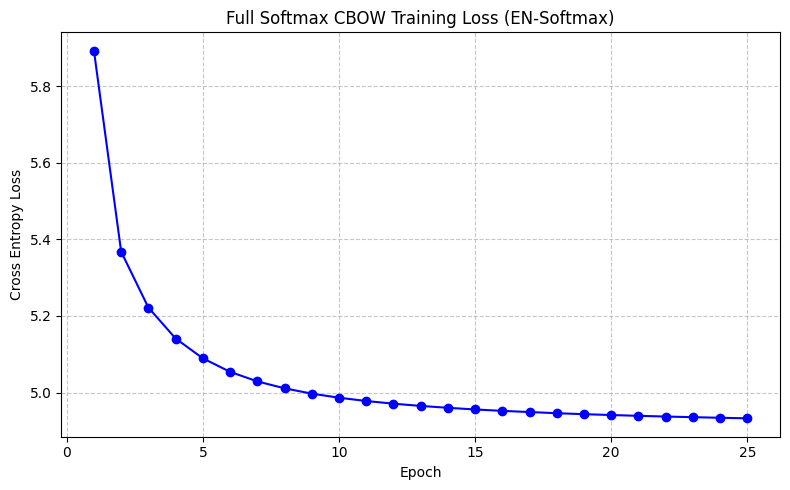

[artifact] saved -> en_embeddings_softmax.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[artifact] final artifact download triggered for en_embeddings_softmax.pkl.
EN-Softmax model successfully trained and saved!


In [17]:
# Cell 75 — EN Softmax
print("--- Preprocessing English ---")
en_encoded, en_stoi, en_itos, en_freq = preprocess_and_build_vocab(en_train_texts)
en_vocab_list = [en_itos[i] for i in range(len(en_itos))]

print("\n--- Training EN-Softmax ---")
en_emb_softmax, en_time_sm, en_loss_sm = train_word2vec_softmax(en_encoded, en_stoi, label="EN-Softmax")

save_pkl("en_embeddings_softmax.pkl", en_emb_softmax, en_vocab_list, en_stoi,
         epoch_losses=en_loss_sm, total_time=en_time_sm, label="EN-Softmax")
print("EN-Softmax model successfully trained and saved!")

### Optional Resume for `HI-NS`
If you are resuming after a crash, run `upload_checkpoint("HI-NS")` in a code cell before executing the training cell below.

--- Preprocessing Hindi ---
Tokenizing corpus...
Encoding corpus...
 -> Vocab size: 169,125 | Corpus tokens (post-prune): 16,283,397

--- Training HI-Negative Sampling ---
[checkpoint] none found for HI-NS, starting from epoch 0.
--- Training HI-NS from epoch 1 to 25 ---


Epoch 1/25 [HI-NS]: 100%|██████████| 3976/3976 [04:57<00:00, 13.36it/s]


Epoch 1/25 - Avg Loss: 1.7476


Epoch 2/25 [HI-NS]: 100%|██████████| 3976/3976 [04:57<00:00, 13.38it/s]


Epoch 2/25 - Avg Loss: 1.3863


Epoch 3/25 [HI-NS]: 100%|██████████| 3976/3976 [04:57<00:00, 13.38it/s]


... (44 outputs left out)

Epoch 25/25 - Avg Loss: 1.0970
[checkpoint] saved -> checkpoint_HI-NS.pt (epoch 25)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[checkpoint] final checkpoint download triggered for checkpoint_HI-NS.pt.
Training for HI-NS complete. Total logged time: 7442.27s (124.04 min).


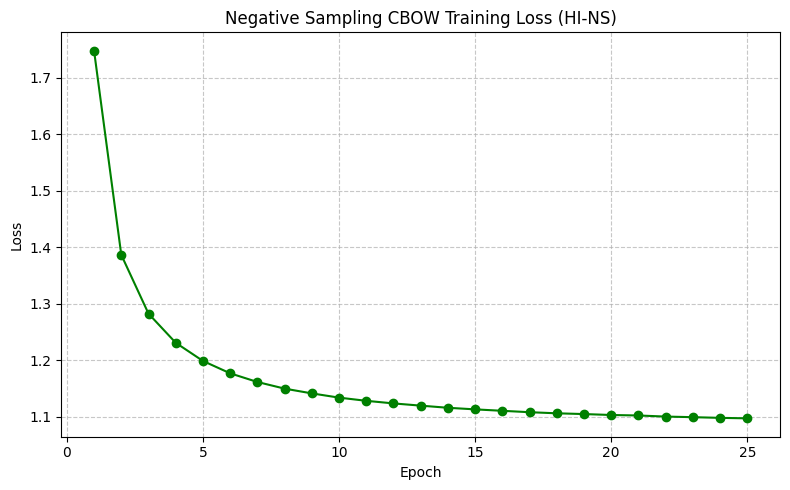

[artifact] saved -> hi_embeddings_ns.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[artifact] final artifact download triggered for hi_embeddings_ns.pkl.
HI-NS model successfully trained and saved!


In [18]:
# Cell 79 — HI Negative Sampling
print("--- Preprocessing Hindi ---")
hi_encoded, hi_stoi, hi_itos, hi_freq = preprocess_and_build_vocab(hi_train_texts)
hi_vocab_list = [hi_itos[i] for i in range(len(hi_itos))]

print("\n--- Training HI-Negative Sampling ---")
hi_emb_ns, hi_time_ns, hi_loss_ns = train_word2vec_ns(hi_encoded, hi_stoi, hi_freq, label="HI-NS")

save_pkl("hi_embeddings_ns.pkl", hi_emb_ns, hi_vocab_list, hi_stoi,
         epoch_losses=hi_loss_ns, total_time=hi_time_ns, label="HI-NS")
print("HI-NS model successfully trained and saved!")

## Final Downloads
Run the next cell after both models finish to download the final artifacts and the shared corpus CSVs.

In [19]:
download_files([
    "en_embeddings_softmax.pkl",
    "checkpoint_EN-Softmax.pt",
    "hi_embeddings_ns.pkl",
    "checkpoint_HI-NS.pt",
    "shared_english_corpus.csv",
    "shared_hindi_corpus.csv"
])

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[download] download triggered for: ['en_embeddings_softmax.pkl', 'checkpoint_EN-Softmax.pt', 'hi_embeddings_ns.pkl', 'checkpoint_HI-NS.pt', 'shared_english_corpus.csv', 'shared_hindi_corpus.csv']
